# Problem Statement

Banyak perusahaan vape yang produknya tidak terjual secara optimal dan mengalami penurunan penjualan setiap bulannya karena gagal mengikuti percepatan perkembangan teknologi. Membantu toko dalam mengidentifikasi produk terlaris dan produk yang sering dibeli bersamaan (seperti Catridge Oxva Slim Kit dan Liquid Oat Drip V7) agar manajemen stok lebih terarah.
Jurnal ini diguanakan untuk tidak ngelakukan kesalahan yang sama

https://senafti.budiluhur.ac.id/senafti/article/view/938

# Import

## Libalry

In [2]:
pip install pandas mlxtend

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
from scipy.stats import zscore
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.preprocessing import LabelEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

## Data

In [4]:
## Import Excel
df = pd.read_csv("Market Basket Analysis- Groceries_dataset.csv")

df

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
...,...,...,...
38760,4471,08-10-2014,sliced cheese
38761,2022,23-02-2014,candy
38762,1097,16-04-2014,cake bar
38763,1510,03-12-2014,fruit/vegetable juice


## head()

In [5]:
# Copy data biar tidak ditiban
df_copy = df.copy()
df_copy.head()

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


## Info

In [6]:
# Info data
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Member_number    38765 non-null  int64
 1   Date             38765 non-null  str  
 2   itemDescription  38765 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.6 MB


Data 

In [7]:
df_copy['Date'] = pd.to_datetime(df_copy['Date'], format='%d-%m-%Y')

In [8]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Member_number    38765 non-null  int64         
 1   Date             38765 non-null  datetime64[us]
 2   itemDescription  38765 non-null  str           
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 1.3 MB


# Cleaning Data

## Missing Value

In [9]:
Missing_count = df_copy.isnull().sum()
Missing_percent = (df_copy.isnull().sum() / len(df_copy)) * 100

# Menggabungkan jumlah dan persentase ke dalam satu DataFrame agar rapi
missing_summary = pd.DataFrame({
    'Jumlah Missing': Missing_count,
    'Persentase (%)': Missing_percent
})

# Mengurutkan dari jumlah missing value terbanyak (opsional)
missing_summary = missing_summary.sort_values(by='Jumlah Missing', ascending=False)

# Memformat angka persentase agar rapi (misal 2 angka di belakang koma)
missing_summary['Persentase (%)'] = missing_summary['Persentase (%)'].round(2)

print("Ringkasan Missing Value:")
print(missing_summary)

Ringkasan Missing Value:
                 Jumlah Missing  Persentase (%)
Member_number                 0             0.0
Date                          0             0.0
itemDescription               0             0.0


Groceries_dataset ini tidak terdapat namanya missing value (data yang kosong), jadi data ini aman untuk digunakan

## Duplikasi

In [10]:
## Duplicated 
SemuaData = df_copy.duplicated().sum()

#Buat jadi %
a = SemuaData / len(df_copy) * 100
print("=" * 50)
print(f"Duplikat: {SemuaData}")
print(f"Duplikat persen: {a:.2f}%")
print("=" * 50)

Duplikat: 759
Duplikat persen: 1.96%


*Terdapat kolom yang duplikasi* pada Groceries_dataset ini, mengatasi data yang duplikasi pada Groceries_dataset ini yaitu dengan *mempertahankannya.* Dikarenakan ini *data penjualalan yang customer bisa membeli lebih banyak barang.*

## Konsistensi

### Date

In [11]:
TypoDate = df_copy["Date"].unique()
print(f"Typo Date: {TypoDate}")
print("=" * 50)

Typo Date: <DatetimeArray>
['2015-07-21 00:00:00', '2015-01-05 00:00:00', '2015-09-19 00:00:00',
 '2015-12-12 00:00:00', '2015-02-01 00:00:00', '2015-02-14 00:00:00',
 '2015-05-08 00:00:00', '2015-12-23 00:00:00', '2015-03-20 00:00:00',
 '2015-02-12 00:00:00',
 ...
 '2014-06-28 00:00:00', '2014-08-18 00:00:00', '2014-11-25 00:00:00',
 '2014-11-03 00:00:00', '2014-07-19 00:00:00', '2014-02-11 00:00:00',
 '2014-09-15 00:00:00', '2014-02-10 00:00:00', '2014-06-29 00:00:00',
 '2014-11-12 00:00:00']
Length: 728, dtype: datetime64[us]


### itemDescription

In [12]:
TypoitemDescription = df_copy["itemDescription"].unique()
print(f"Typo itemDescription: {TypoitemDescription}")
print("=" * 50)

Typo itemDescription: <ArrowStringArray>
[       'tropical fruit',            'whole milk',             'pip fruit',
      'other vegetables',            'rolls/buns',            'pot plants',
          'citrus fruit',                  'beef',           'frankfurter',
               'chicken',
 ...
        'flower (seeds)',                  'rice',                   'tea',
        'salad dressing',  'specialty vegetables',        'pudding powder',
           'ready soups',       'make up remover',        'toilet cleaner',
 'preservation products']
Length: 167, dtype: str


Pada Groceries_dataset ini tidak terdapat data yang typo (Salah penulisian/pengetikan) yang membuat data Groceries_dataset ini bisa diperiksa lebih lanjut.

## Outlier

### Encoder

In [13]:
# Inisialisasi LabelEncoder
le = LabelEncoder()

# Daftar kolom yang ingin di-encode
kolom_kategorikal = [
    "Date", "itemDescription"
]

# Melakukan encoding untuk setiap kolom dan menyimpannya dengan tambahan suffix _C
for col in kolom_kategorikal:
    df_copy[f"{col}_C"] = le.fit_transform(df_copy[col].astype(str))

# Menampilkan beberapa kolom hasil encoding teratas
df_copy[[col + "_C" for col in kolom_kategorikal]]

,Date_C,itemDescription_C
0,565,156
1,368,164
2,625,109
3,709,102
4,395,164
...,...,...
38760,280,135
38761,53,19
38762,105,17
38763,336,64


### Bloxplot

#### Member_number

C:\Users\rakad\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


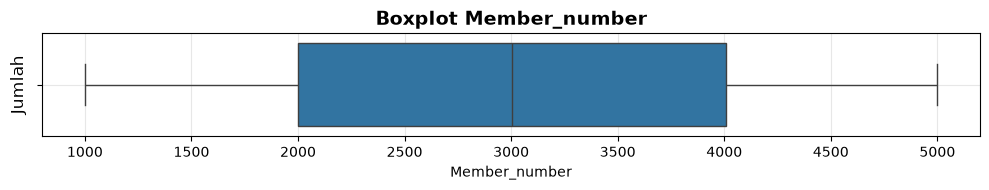

In [14]:
df_box = df_copy.copy()

# Buat boxplot Member_number
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["Member_number"])
plt.title("Boxplot Member_number", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

#### Date

C:\Users\rakad\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


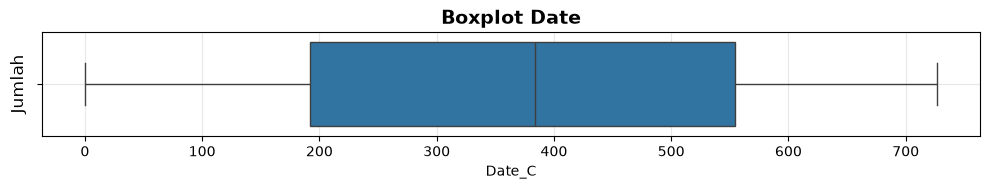

In [15]:
# Buat boxplot Date
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["Date_C"])
plt.title("Boxplot Date", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

#### itemDescription

C:\Users\rakad\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


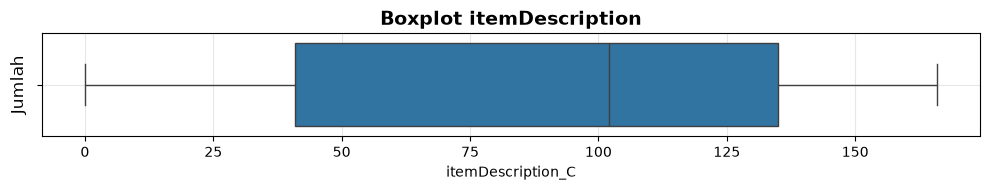

In [16]:
# Buat boxplot item Description
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["itemDescription_C"])
plt.title("Boxplot itemDescription", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

In [17]:
kolom_numerik = df_copy.select_dtypes(include=["float64", "int64"]).columns
for i in kolom_numerik :
    Q1 = df_copy[i].quantile(0.25)
    Q3 = df_copy[i].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier = (df_copy[i] < lower) | (df_copy[i] > upper)
    jumlah_outlier = outlier.sum() # Mengetahui jumlah outlier pada kolom
    persentase_outlier = jumlah_outlier/len(outlier) * 100 # Mengetahui persentase outlier pada kolom
    print(f"Jumlah Outlier pada Kolom {i} : {jumlah_outlier}")
    print(f"Persentase Outlier pada Kolom {i} : {persentase_outlier:.2f}%\n")
print("=" * 100)

Jumlah Outlier pada Kolom Member_number : 0
Persentase Outlier pada Kolom Member_number : 0.00%

Jumlah Outlier pada Kolom Date_C : 0
Persentase Outlier pada Kolom Date_C : 0.00%

Jumlah Outlier pada Kolom itemDescription_C : 0
Persentase Outlier pada Kolom itemDescription_C : 0.00%



Setelah mencari Outlier dengan Boxplot dan IQR pada data itemDescription ini, bisa disimpulkan bahwa data itemDescription ini tidak terdapat Outlier.

## Uji Normalitas Data

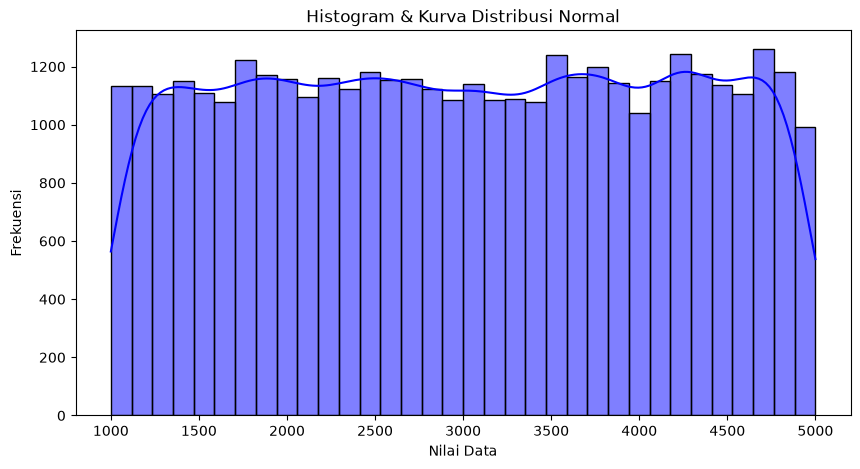

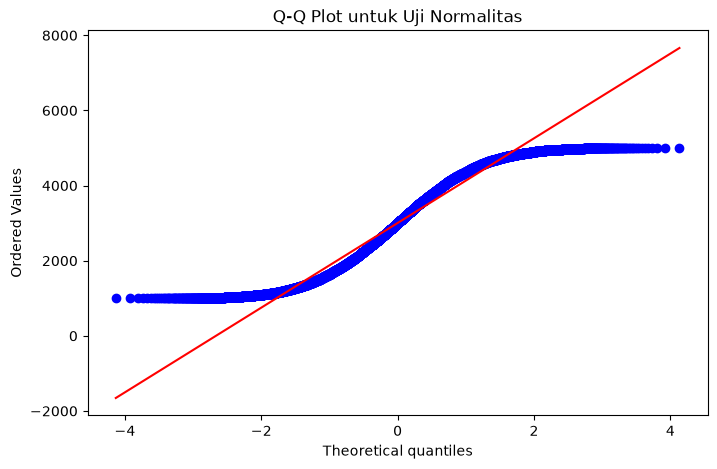

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Member_number'], kde=True, color='blue') # Ganti 'Member_number' dengan kolom numerik Anda
plt.title('Histogram & Kurva Distribusi Normal')
plt.xlabel('Nilai Data')
plt.ylabel('Frekuensi')
plt.show()

# 2. Q-Q Plot (Quantile-Quantile Plot)
plt.figure(figsize=(8, 5))
stats.probplot(df['Member_number'], dist="norm", plot=plt)
plt.title('Q-Q Plot untuk Uji Normalitas')
plt.show()

Setelah Normalitas Data pada data Groceries_dataset ini, itu cukup setabil.

## EDA

### Unvariate

<Figure size 1200x800 with 0 Axes>

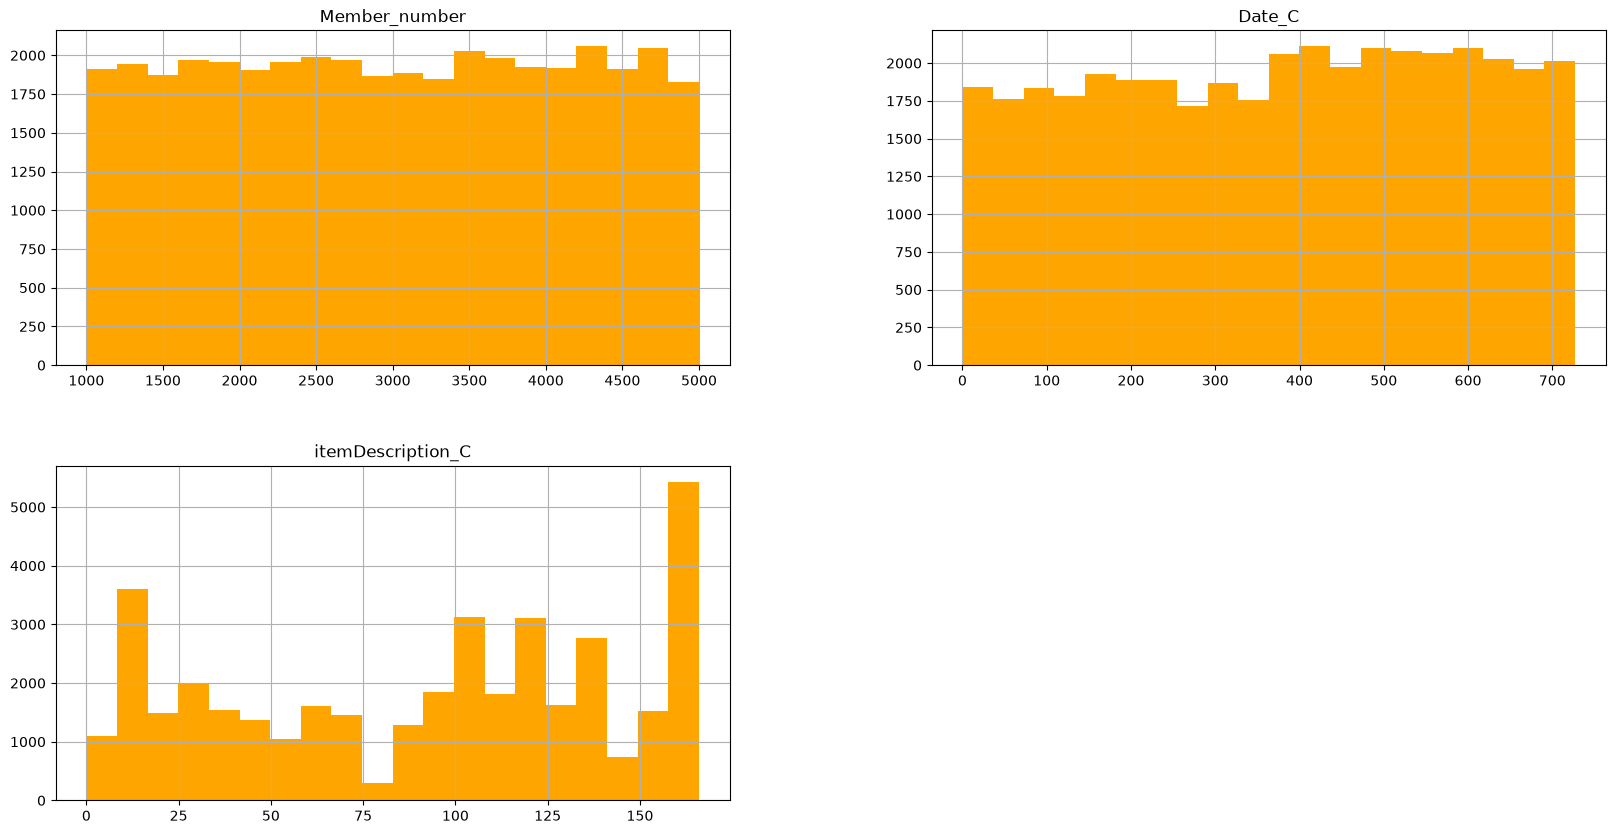

In [19]:
kolom_pilihan = [
    "Member_number", 
    "Date_C", 
    "itemDescription_C"
]

plt.figure(figsize=(12, 8))
df_copy[kolom_pilihan].hist(bins=20, figsize=(20, 10), color="orange")
plt.title("Distribusi Variable Numerik")
plt.show()

### Headmap

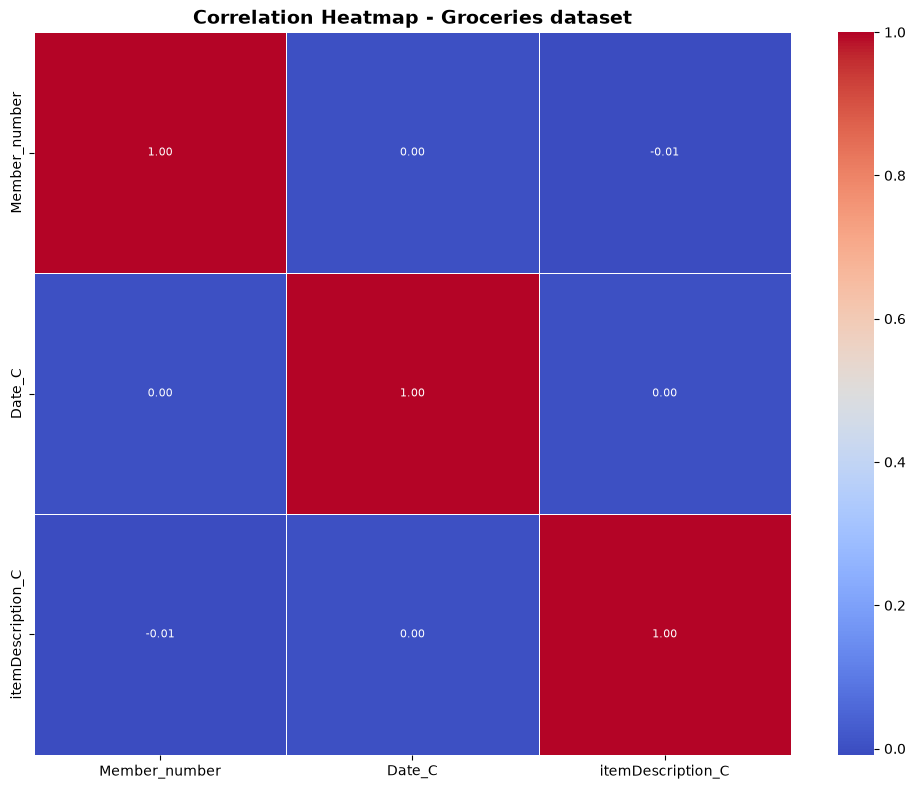

In [20]:
corr = df_copy[[
    "Member_number", 
    "Date_C", 
    "itemDescription_C"
               ]].corr()

# Membuat plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, annot_kws={"size": 8})

plt.title("Correlation Heatmap - Groceries dataset", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Analisis

## Jumlah Items

In [21]:
product_counts_grouped = df.groupby('itemDescription').size().reset_index(name='jumlah')
product_counts_grouped

,itemDescription,jumlah
0,Instant food products,60
1,UHT-milk,323
2,abrasive cleaner,22
3,artif. sweetener,29
4,baby cosmetics,3
...,...,...
162,white bread,362
163,white wine,176
164,whole milk,2502
165,yogurt,1334


In [22]:
total_item = product_counts_grouped['jumlah'].sum()
product_counts_grouped['persen'] = (product_counts_grouped['jumlah'] / total_item) * 100

# 4. Mengurutkan dari yang tertinggi (terbanyak) ke terendah
product_counts_grouped = product_counts_grouped.sort_values(by='jumlah', ascending=False).reset_index(drop=True)

# (Opsional) Memformat kolom persen agar rapi (misal 2 angka dibelakang koma)
product_counts_grouped['persen'] = product_counts_grouped['persen'].round(2)

# Menampilkan hasil teratas
product_counts_grouped

,itemDescription,jumlah,persen
0,whole milk,2502,6.45
1,other vegetables,1898,4.90
2,rolls/buns,1716,4.43
3,soda,1514,3.91
4,yogurt,1334,3.44
...,...,...,...
162,make up remover,5,0.01
163,bags,4,0.01
164,baby cosmetics,3,0.01
165,kitchen utensil,1,0.00


In [23]:
data = list(df["itemDescription"].apply(lambda x:x.split(",") ))
data

[['tropical fruit'],
 ['whole milk'],
 ['pip fruit'],
 ['other vegetables'],
 ['whole milk'],
 ['rolls/buns'],
 ['other vegetables'],
 ['pot plants'],
 ['whole milk'],
 ['tropical fruit'],
 ['citrus fruit'],
 ['beef'],
 ['frankfurter'],
 ['chicken'],
 ['butter'],
 ['fruit/vegetable juice'],
 ['packaged fruit/vegetables'],
 ['chocolate'],
 ['specialty bar'],
 ['other vegetables'],
 ['butter milk'],
 ['whole milk'],
 ['tropical fruit'],
 ['tropical fruit'],
 ['bottled water'],
 ['yogurt'],
 ['sausage'],
 ['other vegetables'],
 ['brown bread'],
 ['yogurt'],
 ['hamburger meat'],
 ['root vegetables'],
 ['pork'],
 ['beef'],
 ['pastry'],
 ['fruit/vegetable juice'],
 ['canned beer'],
 ['root vegetables'],
 ['citrus fruit'],
 ['sausage'],
 ['tropical fruit'],
 ['berries'],
 ['canned beer'],
 ['butter milk'],
 ['coffee'],
 ['pastry'],
 ['rolls/buns'],
 ['misc. beverages'],
 ['root vegetables'],
 ['sausage'],
 ['canned beer'],
 ['ham'],
 ['turkey'],
 ['whole milk'],
 ['whole milk'],
 ['packaged f

### One-Hot Encoder

In [24]:
# 2. Membuat tabel matriks (One-Hot Encoding)
basket = (df_copy.groupby(['Member_number', 'itemDescription'])['itemDescription']
          .count().unstack().reset_index().fillna(0)
          .set_index(['Member_number']))

# 3. Fungsi untuk mengubah nilai menjadi 1 atau 0
def encode_units(x):
    if x <= 0:
        return 0
    if x >= 1:
        return 1

# PERBAIKAN: Menggunakan .map() menggantikan .applymap()
basket_sets = basket.map(encode_units)

# Menampilkan beberapa kolom pertama dari hasil One-Hot Encoding
print("Hasil One-Hot Encoding (beberapa kolom produk):")
basket_sets.iloc[:, :]

Hasil One-Hot Encoding (beberapa kolom produk):


itemDescription,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
Member_number,,,,,,,,,,,,,,,,,,,,,
1000,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,0
1001,0,0,0,0,0,0,0,0,1,0,...,0,0,0,1,0,1,0,1,0,0
1002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1003,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
4998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Menghitung Support

In [25]:
frequent_itemsets = apriori(basket_sets, min_support=0.01, use_colnames=True, verbose =1)
frequent_itemsets

Processing 13340 combinations | Sampling itemset size 2

C:\Users\rakad\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Processing 380 combinations | Sampling itemset size 543


,support,itemsets
0,0.015393,frozenset({Instant food products})
1,0.078502,frozenset({UHT-milk})
2,0.031042,frozenset({baking powder})
3,0.119548,frozenset({beef})
4,0.079785,frozenset({berries})
...,...,...
3011,0.011031,"frozenset({soda, whole milk, yogurt, whipped/s..."
3012,0.010518,"frozenset({yogurt, whole milk, other vegetable..."
3013,0.013597,"frozenset({sausage, yogurt, whole milk, other ..."
3014,0.010005,"frozenset({shopping bags, yogurt, whole milk, ..."


## Rules

In [26]:
# Membuat Association Rules (Aturan Asosiasi)
# Menggunakan metric 'lift' untuk melihat seberapa kuat hubungan antar produk
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)

# Mengubah kolom frozenset (antecedents & consequents) menjadi string biasa
rules_tableau = rules.copy()
rules_tableau['antecedents'] = rules_tableau['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_tableau['consequents'] = rules_tableau['consequents'].apply(lambda x: ', '.join(list(x)))

# Memilih kolom penting yang akan dibawa ke Tableau
export_data = rules_tableau[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
export_data

,antecedents,consequents,support,confidence,lift
0,liquor,whole milk,0.016675,0.631068,1.377325
1,mustard,whole milk,0.014110,0.604396,1.319112
2,"sausage, UHT-milk",other vegetables,0.011801,0.638889,1.696450
3,"UHT-milk, yogurt",other vegetables,0.014366,0.615385,1.634039
4,"beef, bottled beer",whole milk,0.013084,0.629630,1.374186
...,...,...,...,...,...
286,"yogurt, soda, whipped/sour cream",whole milk,0.011031,0.641791,1.400729
287,"other vegetables, rolls/buns, yogurt, bottled ...",whole milk,0.010518,0.745455,1.626978
288,"sausage, other vegetables, rolls/buns, yogurt",whole milk,0.013597,0.688312,1.502261
289,"other vegetables, shopping bags, rolls/buns, y...",whole milk,0.010005,0.709091,1.547613


## Suport Only

In [27]:
# Mengambil top 20 berdasarkan support tertinggi
frequent_items_top_20 = frequent_itemsets.sort_values(by='support', ascending=False).reset_index(drop=True)

# Mengubah frozenset menjadi string biasa (menghilangkan kata frozenset)
frequent_items_top_20['itemsets'] = frequent_items_top_20['itemsets'].apply(lambda x: ', '.join(list(x)))

# Menampilkan hasil
frequent_items_top_20

,support,itemsets
0,0.458184,whole milk
1,0.376603,other vegetables
2,0.349666,rolls/buns
3,0.313494,soda
4,0.282966,yogurt
...,...,...
3011,0.010005,"other vegetables, whole milk, semi-finished bread"
3012,0.010005,"white bread, other vegetables, shopping bags"
3013,0.010005,"other vegetables, pork, domestic eggs"
3014,0.010005,"shopping bags, yogurt, whole milk, other veget..."


minimum support,

In [28]:
# 1. Kode Anda sebelumnya
frequent = frequent_itemsets['itemsets'].apply(lambda x: len(x))
top_pairs = frequent_itemsets[frequent == 2].copy()

# 2. TAMBAHKAN BARIS INI: Mengubah frozenset menjadi teks biasa (string)
top_pairs['itemsets'] = top_pairs['itemsets'].apply(lambda x: ', '.join(list(x)))

# 3. Menampilkan hasil tanpa kata "frozenset"
top_pairs

,support,itemsets
116,0.010518,"UHT-milk, beef"
117,0.014879,"UHT-milk, bottled beer"
118,0.021293,"UHT-milk, bottled water"
119,0.012314,"brown bread, UHT-milk"
120,0.010518,"butter, UHT-milk"
...,...,...
1237,0.047717,"white bread, whole milk"
1238,0.028476,"white bread, yogurt"
1239,0.023602,"white wine, whole milk"
1240,0.016419,"white wine, yogurt"


In [29]:
top_pairs_new = top_pairs.sort_values(by='support', ascending=False)
top_pairs_new

,support,itemsets
1050,0.191380,"other vegetables, whole milk"
1140,0.178553,"rolls/buns, whole milk"
1209,0.151103,"whole milk, soda"
1241,0.150590,"yogurt, whole milk"
1031,0.146742,"other vegetables, rolls/buns"
...,...,...
212,0.010005,"beverages, bottled beer"
504,0.010005,"chewing gum, shopping bags"
889,0.010005,"shopping bags, hygiene articles"
882,0.010005,"newspapers, hygiene articles"


## Heatmap

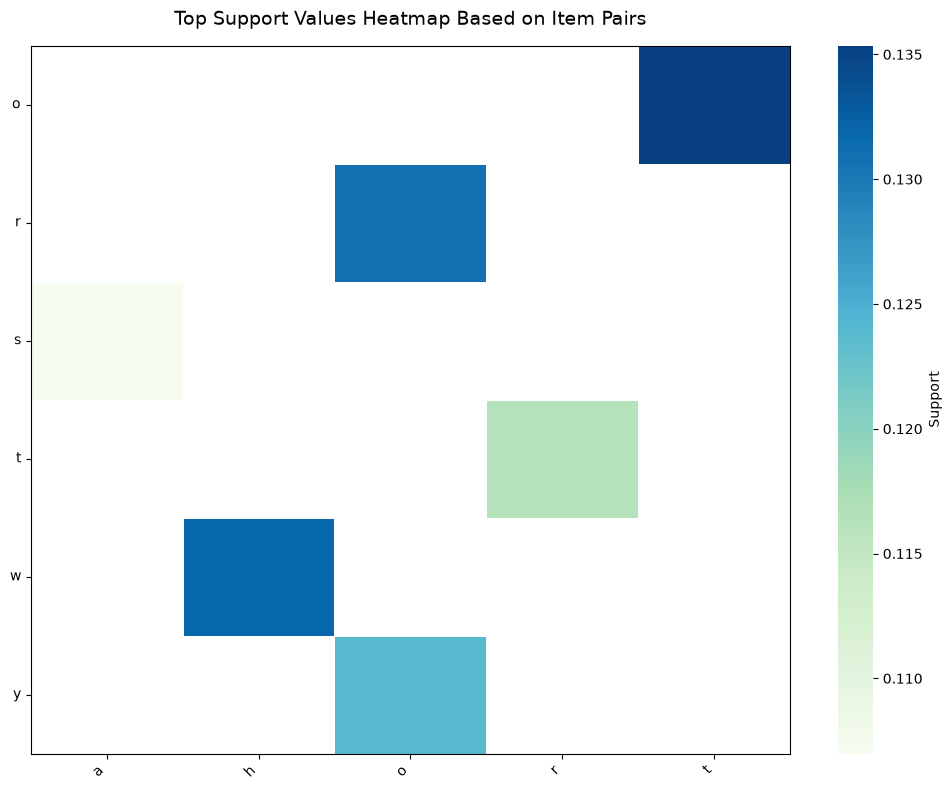

In [30]:
# ---> TAMBAHKAN BARIS INI: Ambil hanya TOP 15 pasangan dengan support tertinggi <---
top_pairs = top_pairs.nlargest(15, 'support')

# Memecah isi itemsets menjadi 'Item 1' dan 'Item 2'
top_pairs['Item 1'] = top_pairs['itemsets'].apply(lambda x: list(x)[0])
top_pairs['Item 2'] = top_pairs['itemsets'].apply(lambda x: list(x)[1])

# Membuat tabel matriks (crosstab) untuk heatmap
heatmap_data = pd.crosstab(
    top_pairs['Item 1'], 
    top_pairs['Item 2'], 
    values=top_pairs['support'], 
    aggfunc='mean', 
    dropna=True
)

# Membuat Visualisasi Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    heatmap_data, 
    cmap="GnBu", 
    annot=False, 
    fmt=".1f", 
    cbar_kws={'label': 'Support'}, 
    linewidths=0.5
)

plt.title("Top Support Values Heatmap Based on Item Pairs", fontsize=14, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

# Menampilkan garis tepi (spines) pada plot
for spine in plt.gca().spines.values():
    spine.set_visible(True)

plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [31]:
hasil = pd.concat([df_copy, export_data], ignore_index=True)
hasil

,Member_number,Date,itemDescription,Date_C,itemDescription_C,antecedents,consequents,support,confidence,lift
0,1808.0,2015-07-21,tropical fruit,565.0,156.0,NaN,NaN,NaN,NaN,NaN
1,2552.0,2015-01-05,whole milk,368.0,164.0,NaN,NaN,NaN,NaN,NaN
2,2300.0,2015-09-19,pip fruit,625.0,109.0,NaN,NaN,NaN,NaN,NaN
3,1187.0,2015-12-12,other vegetables,709.0,102.0,NaN,NaN,NaN,NaN,NaN
4,3037.0,2015-02-01,whole milk,395.0,164.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
39051,NaN,NaT,NaN,NaN,NaN,"yogurt, soda, whipped/sour cream",whole milk,0.011031,0.641791,1.400729
39052,NaN,NaT,NaN,NaN,NaN,"other vegetables, rolls/buns, yogurt, bottled ...",whole milk,0.010518,0.745455,1.626978
39053,NaN,NaT,NaN,NaN,NaN,"sausage, other vegetables, rolls/buns, yogurt",whole milk,0.013597,0.688312,1.502261
39054,NaN,NaT,NaN,NaN,NaN,"other vegetables, shopping bags, rolls/buns, y...",whole milk,0.010005,0.709091,1.547613


# Kesimpulan

Data Groceries dataset ini tidak terdapat Missing Value, Outlier dan Typo (salah ketik). Namum terdapat data yang terduplikasi, solusi untuk mengatasi data yang terduplikasi ini adalah dengan cara membiarkannya, dikarenakan bahwa Customer bisa membeli lebih dari satu barang yang sama.

Setelah menganalisis Market basket, bisa disimpulkan bahwa barang yang kemungkinan dibeli dari semua barang yang di beli yaitu Whole milk.

In [32]:
'''Export df_copy menjadi excel'''
df_subset = df_copy[['Member_number', 'Date', 'itemDescription']].copy()
df_subset.to_excel("Groceries_dataset Bersih.xlsx")

In [33]:
top_pairs.to_excel("top_pairs.xlsx")

In [34]:
export_data.to_excel("export_data.xlsx")

In [35]:
frequent_items_top_20.to_excel("frequent_items_top_20.xlsx")